# Notebook 03 — Clustering Profil Siswa (Eksplorasi Tambahan)

Tujuan notebook ini adalah eksplorasi pengelompokan profil siswa menggunakan K-Means pada fitur numerik/ordinal yang tersedia. Klaster bukan kategori resmi siswa, bukan diagnosis, dan tidak membuktikan sebab-akibat. Jalankan semua sel berurutan.

In [1]:
from pathlib import Path
import zipfile, urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists(): ROOT = ROOT.parent
raw_path = ROOT / "data" / "raw" / "student-mat.csv"
raw_path.parent.mkdir(parents=True, exist_ok=True)
if not raw_path.exists():
    url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
    zip_path = ROOT / "data" / "raw" / "student-performance.zip"
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        member = next(n for n in z.namelist() if n.endswith("student-mat.csv"))
        raw_path.write_bytes(z.read(member))
df = pd.read_csv(raw_path, sep=";")
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 1. Pemilihan fitur untuk clustering
Fitur yang dipilih menggambarkan kebiasaan belajar, absensi, dan dukungan keluarga. Nilai akhir (`G3`) tidak digunakan untuk membentuk klaster agar pengelompokan tidak sekadar mengelompokkan berdasarkan target nilai.

In [2]:
cluster_features = [c for c in ["studytime", "failures", "absences", "freetime", "goout", "Dalc", "Walc", "health", "famrel"] if c in df.columns]
X = df[cluster_features].copy()
X = X.fillna(X.median(numeric_only=True))
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Fitur:", cluster_features)
print("Data yang digunakan:", X_scaled.shape)

Fitur: ['studytime', 'failures', 'absences', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'famrel']
Data yang digunakan: (395, 9)


## 2. Menentukan jumlah klaster secara eksploratif
Bandingkan inertia dan silhouette untuk beberapa nilai K. Silhouette tidak selalu menjadi satu-satunya dasar; interpretabilitas dan ukuran tiap klaster juga perlu dipertimbangkan.

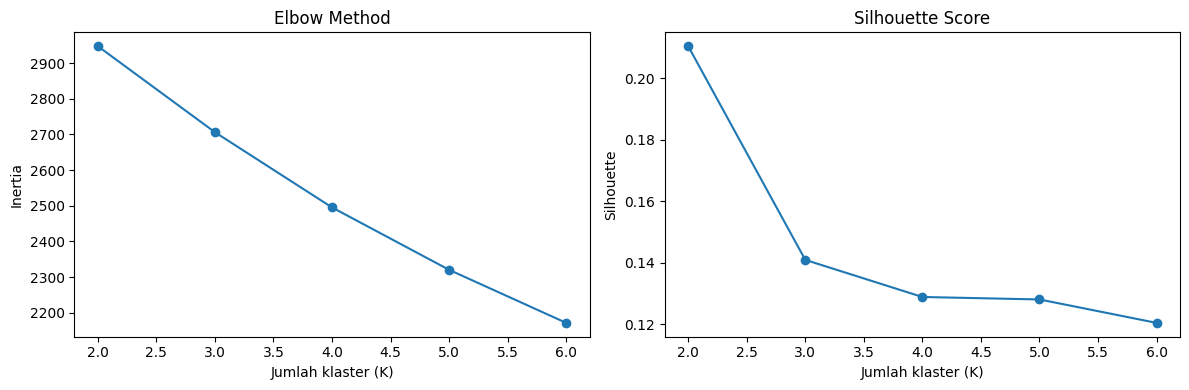

,k,inertia,silhouette
0,2,2947.311103,0.210446
1,3,2706.168355,0.140939
2,4,2495.355110,0.128875
3,5,2320.442666,0.128070
4,6,2171.720742,0.120450


In [3]:
ks = range(2, 7)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(ks), inertias, marker="o")
ax[0].set(title="Elbow Method", xlabel="Jumlah klaster (K)", ylabel="Inertia")
ax[1].plot(list(ks), silhouettes, marker="o")
ax[1].set(title="Silhouette Score", xlabel="Jumlah klaster (K)", ylabel="Silhouette")
plt.tight_layout(); plt.show()
pd.DataFrame({"k": list(ks), "inertia": inertias, "silhouette": silhouettes})

## 3. Membentuk dan menafsirkan klaster

In [4]:
best_k = int(list(ks)[int(np.argmax(silhouettes))])
model = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
df_cluster = df.copy()
df_cluster["cluster"] = model.fit_predict(X_scaled)
print("K terpilih berdasarkan silhouette tertinggi:", best_k)
print("Jumlah anggota per klaster:")
display(df_cluster["cluster"].value_counts().sort_index().rename("jumlah_siswa").to_frame())
print("Rata-rata fitur per klaster:")
display(df_cluster.groupby("cluster")[cluster_features].mean().round(2))

K terpilih berdasarkan silhouette tertinggi: 2
Jumlah anggota per klaster:


,jumlah_siswa
cluster,
0,275
1,120


Rata-rata fitur per klaster:


,studytime,failures,absences,freetime,goout,Dalc,Walc,health,famrel
cluster,,,,,,,,,
0,2.21,0.19,4.59,3.06,2.75,1.09,1.67,3.43,4.02
1,1.64,0.66,8.28,3.63,3.92,2.37,3.72,3.83,3.77


## 4. Catatan interpretasi dan batasan

- Klaster bersifat eksploratif dan sensitif terhadap pemilihan fitur, skala, dan jumlah klaster.
- Profil rata-rata tidak boleh digunakan untuk memberi label negatif pada siswa.
- Dataset observasional tidak membuktikan bahwa kebiasaan tertentu menyebabkan nilai tinggi/rendah.
- Periksa jumlah anggota tiap klaster dan karakteristiknya sebelum menyimpulkan kegunaan analisis.